# 02 · Busca, recall@k e limiar (item 03)
Busca híbrida: embeddings `multilingual-e5-small` + FAISS fundidos com BM25 por RRF. Medimos recall@1/@3/@5 e escolhemos o limiar de recusa pelo gráfico da maior similaridade de cosseno.

In [1]:
import sys, pathlib
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from assistente.config import CONFIG

In [2]:
from assistente.ingest import carregar
from assistente.retriever import Buscador, recall_at_k, scores_top1, melhor_limiar
from assistente.evaluate import carregar_perguntas

buscador = Buscador(carregar()).indexar()
buscador.salvar()
perguntas = carregar_perguntas()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [3]:
recall_at_k(buscador, perguntas)

{'recall@1': 0.5540540540540541,
 'recall@3': 0.7972972972972973,
 'recall@5': 0.8648648648648649}

## Distribuição de score: respondíveis × "não consta"

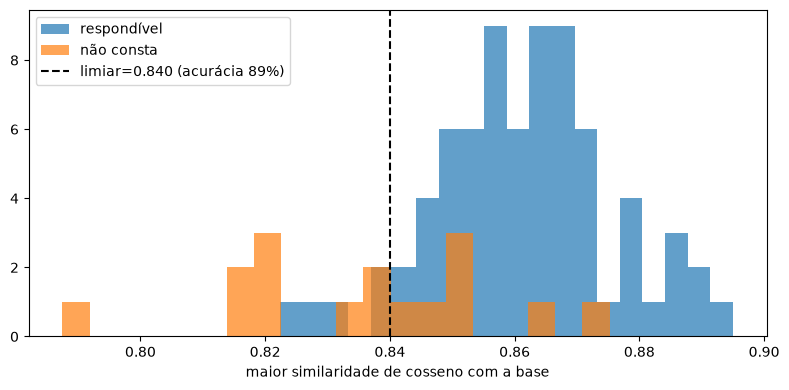

In [4]:
import pandas as pd, matplotlib.pyplot as plt

s = pd.DataFrame(scores_top1(buscador, perguntas))
lim, acc = melhor_limiar(s.to_dict('records'))
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(s[~s.deve_recusar].score, bins=20, alpha=.7, label='respondível')
ax.hist(s[s.deve_recusar].score, bins=20, alpha=.7, label='não consta')
ax.axvline(lim, color='k', ls='--', label=f'limiar={lim:.3f} (acurácia {acc:.0%})')
ax.set_xlabel('maior similaridade de cosseno com a base'); ax.legend(); plt.tight_layout()
plt.savefig(RAIZ/'docs'/'limiar.png', dpi=150); plt.show()

**Justificativa do limiar (0,84):** é o ponto de maior acurácia (89%) na separação entre respondíveis e "não consta". Ele mantém 71/74 respondíveis (96%) e barra 9/16 "não consta", justamente as fora do tema. As 7 que passam são do tema, mas pedem um fato ausente da base; quem tem que barrar essas é a regra do prompt (recusa em 2 camadas).